# Seminar toolkit for homework 1

The code is taken from `ai-agent-01.ipynb`, the cells are in working order from top to bottom. All strings are in English.

## Setup

In [1]:
import os, re, sys, json, time, ast, operator, subprocess
from pathlib import Path
from dataclasses import dataclass, field
from concurrent.futures import ThreadPoolExecutor
import threading
import requests
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field, ValidationError

try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass
#try:
#    from kaggle_secrets import UserSecretsClient
#    os.environ.setdefault("OPENROUTER_API_KEY", UserSecretsClient().get_secret("OPENROUTER_API_KEY"))
#except Exception:
#    pass

assert os.getenv("OPENROUTER_API_KEY"), "no key: put it in .env next to the notebook or in Kaggle Secrets"

CHAT_URL = "https://openrouter.ai/api/v1/chat/completions"
HEADERS = {"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}",
           "HTTP-Referer": "https://postypashki.ru", "X-Title": "agents-course-seminar01"}
MODELS = {"cheap": "openai/gpt-4o-mini", "mid": "anthropic/claude-haiku-4.5", "strong": "anthropic/claude-sonnet-4.6"}
COLORS = {"violet": "#5436A3", "amber": "#F09000", "teal": "#00838F", "red": "#C43C3C", "grey": "#787882"}
DATA = next((p for p in [Path("data"), Path("/kaggle/input/datasets/artmakar04/"), Path("/kaggle/input/seminar01-data/data")]
             if (p / "compare_10.jsonl").exists()), Path("data"))
TRACES, IMG = Path("traces"), Path("img")
TRACES.mkdir(exist_ok=True)
IMG.mkdir(exist_ok=True)

## Model call, ledger, request retry

In [2]:
@dataclass
class Ledger:
    calls: list = field(default_factory=list)

    def add(self, tag, model, usage, seconds=0.0):
        p, c = usage.get("prompt_tokens", 0), usage.get("completion_tokens", 0)
        cost = usage.get("cost") or 0.0
        self.calls.append({"tag": tag, "model": model.split("/")[-1], "prompt": p, "completion": c,
                           "cost": cost, "seconds": round(seconds, 2)})
        return cost

    @property
    def total(self):
        return sum(c["cost"] for c in self.calls)

    def table(self):
        df = pd.DataFrame(self.calls)
        return df.groupby(["tag", "model"]).agg(calls=("cost", "size"), prompt=("prompt", "sum"),
                                                completion=("completion", "sum"), cost=("cost", "sum"),
                                                seconds=("seconds", "sum")).round(5)

ledger = Ledger()

In [3]:
def post_with_retry(body, attempts=6):
    problem = "no response"
    for attempt in range(attempts):
        retry_after = None
        try:
            r = requests.post(CHAT_URL, json=body, headers=HEADERS, timeout=120)
        except requests.RequestException as e:
            problem = type(e).__name__
        else:
            if r.status_code == 200:
                return r.json()
            problem = f"HTTP {r.status_code} : {r.text[:5000]}"
            if r.status_code not in (429, 500, 502, 503, 504):
                break
            retry_after = r.headers.get("Retry-After")
        if attempt < attempts - 1:
            time.sleep(min(60, float(retry_after)) if retry_after and retry_after.isdigit() else min(60, 4 * 2 ** attempt))
    raise RuntimeError(problem)


In [4]:
LOCAL = threading.local()

def chat(messages, model, tools=None, tag="chat", temperature=None):
    body = {"model": model, "messages": messages, "usage": {"include": True}}
    if tools:
        body["tools"] = tools
        body["tool_choice"] = "auto"
    if temperature is not None:
        body["temperature"] = temperature
    started = time.perf_counter()
    data = post_with_retry(body)
    LOCAL.cost = getattr(LOCAL, "cost", 0.0) + ledger.add(tag, model, data.get("usage") or {}, time.perf_counter() - started)
    return data["choices"][0]["message"]

## Structured answer and task loading

In [5]:
class Answer(BaseModel):
    reasoning: str = Field(description="solution steps in two or three sentences")
    final: str = Field(description="final answer only: a number or a short phrase")

SCHEMA_PROMPT = "Answer strictly with a single JSON object matching this schema, no text around it, strings on one line, no extra indentation, \t, \n:\n{schema}"

def json_from(text):
    m = re.search(r"\{.*\}", text or "", re.S)
    if not m:
        raise ValueError("no JSON in the response")
    return json.loads(m.group(0), strict=False)

In [6]:
def ask_structured(question, model, schema=Answer, attempts=3):
    messages = [
        {"role": "system", "content": SCHEMA_PROMPT.format(schema=json.dumps(schema.model_json_schema(), ensure_ascii=False))},
        {"role": "user", "content": question}
    ]
    for _ in range(attempts):
        msg = chat(messages, model, tag="struct")
        try:
            return schema.model_validate(json_from(msg["content"]))
        except (ValidationError, ValueError) as e:
            messages += [msg, {"role": "user", "content": f"The answer failed the structure check: {e}. Return the answer in the strict JSON schema"}]
    raise ValueError("The model failed")

In [7]:
def load_tasks(name):
    return [json.loads(line) for line in (DATA / name).read_text(encoding="utf-8").splitlines() if line.strip()]

## Answer checking and summary

In [8]:
def normalize(text):
    text = re.sub(r"[^\w\s]", " ", str(text).lower().replace(",", ""))
    text = re.sub(r"\b(a|an|the)\b", " ", text)
    return " ".join(text.split())

MONTHS = "january|february|march|april|may|june|july|august|september|october|november|december"
MONTH_LIST = MONTHS.split("|")
NUMBER_WORDS = {w: n for n, w in enumerate("zero one two three four five six seven eight nine ten eleven twelve thirteen "
                                            "fourteen fifteen sixteen seventeen eighteen nineteen twenty".split())}
NUMBER_WORDS.update({"thirty": 30, "forty": 40, "fifty": 50, "sixty": 60, "seventy": 70, "eighty": 80, "ninety": 90})
COUNT = rf"(?:[\d.]+|{'|'.join(NUMBER_WORDS)})(?:\s+[a-z]+)?"

def date_pairs(text):
    text = str(text).lower()
    pairs = {(int(d), m) for d, m in re.findall(rf"\b(\d{{1,2}})(?:st|nd|rd|th)?\s+(?:of\s+)?({MONTHS})\b", text)}
    pairs |= {(int(d), m) for m, d in re.findall(rf"\b({MONTHS})\s+(\d{{1,2}})\b", text)}
    pairs |= {(int(d), MONTH_LIST[int(m) - 1]) for m, d in re.findall(r"\b\d{4}-(0[1-9]|1[0-2])-(\d{2})\b", text)}
    return pairs

def numbers_in(text):
    text = str(text).lower().replace(",", "")
    nums = {float(x) for x in re.findall(r"\d+(?:\.\d+)?", text)}
    return nums | {float(NUMBER_WORDS[w]) for w in re.findall(r"[a-z]+", text) if w in NUMBER_WORDS}

def is_correct(task, answer):
    if task["source"] == "gsm8k":
        nums = re.findall(r"-?\d+(?:\.\d+)?", str(answer).replace(",", ""))
        return bool(nums) and abs(float(nums[-1]) - float(task["answer"])) < 1e-6
    gold = task["answer"]
    if normalize(gold) in normalize(answer):
        return True
    if date_pairs(gold):
        return bool(date_pairs(gold) & date_pairs(answer))
    if re.fullmatch(COUNT, normalize(gold)):
        return numbers_in(gold) <= numbers_in(answer)
    return False

def check(gold, answer):
    return is_correct({"source": "fresh", "answer": gold}, answer)

assert check("15 March", "March 15, 2026") and check("15 March", "15 March 2026")
assert check("15 March", "2026-03-15") and check("15 March", "the 15th of March")
assert not check("15 March", "March 16, 2026") and not check("15 March", "15 April")
assert check("two people", "2") and check("two people", "Two killed") and check("4,500", "about 4,500")
assert not check("two people", "6") and not check("4,500", "519")
assert not check("Apollo 11", "Apollo 12") and not check("Apollo 11", "11")

def summary(config, model, n, correct, cost, steps, seconds=0.0):
    return {"config": config, "model": model.split("/")[-1], "n": n, "accuracy": round(correct / n, 2),
            "cost_per_task": round(cost / n, 5), "cost_per_correct": round(cost / correct, 5) if correct else float("inf"),
            "avg_steps": round(steps, 2), "avg_seconds": round(seconds, 1)}

## Tools

In [9]:
from tools import (TOOLS, register, CalcArgs, calculator, WikiSearchArgs, WikiPageFindArgs,
                  wiki_search, wiki_page_find, TavilyArgs, tavily_search, ExecArgs, python_exec)

In [10]:
register(calculator, CalcArgs, "Evaluates an arithmetic expression: numbers, parentheses, + - * / ** %")
register(wiki_search, WikiSearchArgs, "Searches the English Wikipedia and returns the introduction of the best matching article. The introduction rarely holds the dates and numbers of a specific event, so read the article text with wiki_page_find")
register(wiki_page_find, WikiPageFindArgs, "Reads the full text of a Wikipedia article by exact title and returns the lines containing the keywords. Events of a given year are listed in overview articles such as \"<year> in <country or field>\", where this tool finds the exact date, number or name")
register(tavily_search, TavilyArgs, "Searches the web via Tavily and returns the top results with snippets")
register(python_exec, ExecArgs, "Runs Python code in a separate process and returns what it printed")

assert calculator("2+2") == "4"
assert calculator("2**10") == "1024"
assert "error" in calculator("__import__('os')")
assert wiki_search("Scott Derrickson").startswith("[Scott Derrickson]")
assert wiki_search("qwxzv 1234567 nonsense") == "No data"
assert python_exec("print(sum(range(10)))") == "45"
assert "ZeroDivisionError" in python_exec("1/0")
assert "Code exceeded 5 sec" in python_exec("import time; time.sleep(10)")
if not os.getenv("TAVILY_API_KEY"):
    assert tavily_search("anything") == "TAVILY_API_KEY is not set"
"tools work"


'tools work'

## Agent loop

In [11]:
SYSTEM = ("You solve tasks. If you need to calculate or look up a fact, call tools instead of guessing. "
          "When the answer is ready, write it as the last line in the format FINAL: <answer>. "
          "For numeric tasks put only the number after FINAL, for factual questions a short phrase.")

CASCADE_SYSTEM = (SYSTEM + " After the FINAL line write one more line CONFIDENCE: <number from 0 to 1>, "
                  "your honest confidence that the FINAL answer is correct.")

@dataclass
class Run:
    question: str
    answer: str
    steps: int
    messages: list
    cost: float = 0.0
    seconds: float = 0.0

def looped(seen, calls):
    keys = [(c["function"]["name"], c["function"]["arguments"]) for c in calls]
    repeated = any(k in seen for k in keys)
    seen.update(keys)
    return repeated

def finish(model, messages, step):
    del messages[-1]
    messages.append({"role": "user", "content": "Tools are no longer available. Answer based on what is already known, with the last line FINAL: <answer>."})
    msg = chat(messages, model, tag="agent")
    messages.append(msg)
    return msg.get("content") or "", step + 1

In [12]:
def run_tool(call):
    name = call["function"]["name"]

    try:
        spec = TOOLS[name]
        args = spec["args"].model_validate_json(call["function"]["arguments"])
        result = spec["fn"](**args.model_dump())
    except Exception as e:
        result = f"Failed to call tool {name}: {e}"
    return {"role": "tool", "tool_call_id" : call["id"], "content": str(result)[:2000]}

In [13]:
def agent_loop(messages, model, tool_names, max_steps):
    seen = set()
    for step in range(1, max_steps + 1):
        msg = chat(messages, model, tools=[TOOLS[n]["schema"] for n in tool_names] or None, tag='agent')
        messages.append(msg)
        calls = msg.get("tool_calls") or []

        if not calls:
            return msg.get("content") or "", step
        if looped(seen, calls) or step == max_steps:
            return finish(model, messages, step)

        messages += [run_tool(c) for c in calls]

In [14]:
def agent(question, model, tool_names, max_steps=8, system=SYSTEM):
    messages = [{"role": "system", "content": system}, {"role": "user", "content": question}]
    LOCAL.cost, started = 0.0, time.perf_counter()
    answer, steps = agent_loop(messages, model, tool_names, max_steps)
    return Run(question, answer, steps, messages, LOCAL.cost, time.perf_counter() - started)

def show_trace(run):
    for m in run.messages[1:]:
        calls = "; ".join(f"{c['function']['name']}{c['function']['arguments']}" for c in m.get("tool_calls") or [])
        text = " ".join((m.get("content") or "").split())[:180]
        print(f"{m['role']:9s}| {text} {calls}")
    print(f"steps: {run.steps}, cost: {run.cost * 100:.3f} ¢, time: {run.seconds:.1f} s")

## Run, traces, table and charts

In [15]:
def final_answer(text):
    m = re.search(r"FINAL:\s*(.+)", text or "")
    return m.group(1).strip() if m else (text or "").strip()

def final_confidence(text):
    m = re.search(r"CONFIDENCE:\s*(\d+(?:\.\d+)?)\s*(%?)", text or "")
    if not m:
        return 0.0
    value = float(m.group(1))
    return min(value / 100 if m.group(2) or value > 1 else value, 1.0)

assert final_confidence("FINAL: x\nCONFIDENCE: 0.8") == 0.8
assert final_confidence("FINAL: x\nCONFIDENCE: 85%") == 0.85
assert final_confidence("FINAL: x") == 0.0

WORKERS = 2

def run_one(task, model, tool_names, folder, system):
    try:
        run = agent(task["question"], model, tool_names, system=system)
    except Exception as e:
        run = Run(task["question"], f"error: {e}", 0, [])
    ok = is_correct(task, final_answer(run.answer))
    (folder / f"{task['id']}.json").write_text(json.dumps({"task": task, "answer": run.answer, "correct": ok, "cost": run.cost,
                                                          "messages": run.messages}, ensure_ascii=False, indent=1), encoding="utf-8")
    return {"config": folder.parent.name, "model": model.split("/")[-1], "id": task["id"], "source": task["source"],
            "correct": ok, "confidence": final_confidence(run.answer), "steps": run.steps, "tool_calls": sum(m["role"] == "tool" for m in run.messages),
            "cost": run.cost, "seconds": round(run.seconds, 1), "answer": final_answer(run.answer)[:60], "gold": task["answer"]}

def run_tasks(tasks, model, tool_names, config, system=SYSTEM, workers=WORKERS):
    folder = TRACES / config / model.split("/")[-1]
    folder.mkdir(parents=True, exist_ok=True)
    with ThreadPoolExecutor(max_workers=workers) as pool:
        rows = list(pool.map(lambda task: run_one(task, model, tool_names, folder, system), tasks))
    return pd.DataFrame(rows)

def report(results):
    rows = [summary(config, model, len(df), int(df["correct"].sum()), df["cost"].sum(), df["steps"].mean(), df["seconds"].mean())
            for (config, model), df in results.groupby(["config", "model"])]
    return pd.DataFrame(rows).sort_values("cost_per_task").reset_index(drop=True)

def money_chart(table, path="img/money_quality.png"):
    fig, ax = plt.subplots(figsize=(8, 5))
    for _, r in table.iterrows():
        color = COLORS["red"] if "cascade" in r["config"] else COLORS["amber"] if "sonnet" in r["model"] else COLORS["violet"]
        ax.scatter(r["cost_per_task"] * 100, r["accuracy"] * 100, s=110, color=color)
        ax.annotate(f"{r['config']}\n{r['model']}", (r["cost_per_task"] * 100, r["accuracy"] * 100),
                    fontsize=8, xytext=(6, 4), textcoords="offset points")
    ax.set_xscale("log")
    ax.set_xlabel("task cost, cents (log scale)")
    ax.set_ylabel("share of correct answers, %")
    ax.grid(alpha=0.3)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return fig

def steps_chart(results):
    g = results.groupby("config").agg(steps=("steps", "mean"), tool_calls=("tool_calls", "mean"), seconds=("seconds", "mean"))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    g[["steps", "tool_calls"]].plot.bar(ax=axes[0], color=[COLORS["violet"], COLORS["teal"]], rot=12)
    axes[0].set_ylabel("average per task")
    g["seconds"].plot.bar(ax=axes[1], color=COLORS["amber"], rot=12)
    axes[1].set_ylabel("seconds per task")
    for ax in axes:
        ax.grid(alpha=0.3, axis="y")
        ax.set_xlabel("")
    fig.tight_layout()
    return fig

CONFIGS = {"no tools": [], "wiki search": ["wiki_search"], "wiki search+page": ["wiki_search", "wiki_page_find"],
           "wiki search+page+tavily": ["wiki_search", "wiki_page_find", "tavily_search"]}

## Bonus: cascade

In [16]:
MEMO = {}

def confident_answer(task, model):
    key = (task["id"], model)
    if key not in MEMO:
        try:
            run = agent(task["question"], model, BEST_TOOLS, system=CASCADE_SYSTEM)
            final = final_answer(run.answer)
            MEMO[key] = {"final": final, "confidence": final_confidence(run.answer), "correct": is_correct(task, final),
                         "cost": run.cost, "steps": run.steps, "seconds": run.seconds}
        except Exception:
            MEMO[key] = {"final": "", "confidence": 0.0, "correct": False, "cost": 0.0, "steps": 0, "seconds": 0.0}
    return dict(MEMO[key])

def seed_memo(results, model):
    for r in results.itertuples():
        MEMO[(r.id, model)] = {"final": r.answer, "confidence": r.confidence, "correct": r.correct,
                               "cost": r.cost, "steps": r.steps, "seconds": r.seconds}

In [17]:
def cascade(task, threshold):
    cheap = confident_answer(task, MODELS['cheap'])
    if cheap["confidence"] >= threshold:
        return {**cheap, "escalated": False}
    mid = confident_answer(task, MODELS['mid'])
    return {**mid, "cost": cheap["cost"] + mid["cost"], "steps": cheap["steps"] + mid["steps"],
            "seconds": cheap["seconds"] + mid["seconds"], "escalated": True}

In [18]:
def cascade_sweep(tasks, thresholds):
    rows = []
    for th in thresholds:
        outs = [cascade(t, th) for t in tasks]
        rows.append({"threshold": th, "accuracy": sum(o["correct"] for o in outs) / len(outs),
                     "cost_per_task": sum(o["cost"] for o in outs) / len(outs),
                     "avg_steps": sum(o["steps"] for o in outs) / len(outs),
                     "avg_seconds": sum(o["seconds"] for o in outs) / len(outs),
                     "escalated": sum(o["escalated"] for o in outs) / len(outs)})
    df = pd.DataFrame(rows)
    df["cost_per_correct"] = df["cost_per_task"] / df["accuracy"].replace(0, float("nan"))
    return df.round(5)

def cascade_chart(df):
    fig, ax = plt.subplots(figsize=(7, 4.2))
    ax.plot(df["cost_per_task"] * 100, df["accuracy"] * 100, marker="o", color=COLORS["red"])
    for _, r in df.iterrows():
        ax.annotate(f"threshold {r['threshold']}, escalated {r['escalated']:.0%}", (r["cost_per_task"] * 100, r["accuracy"] * 100),
                    xytext=(6, -12), textcoords="offset points", fontsize=8)
    ax.set_xlabel("task cost, cents")
    ax.set_ylabel("share of correct, %")
    ax.grid(alpha=0.3)
    return fig

def confidence_chart(tasks, model):
    df = pd.DataFrame([confident_answer(t, model) for t in tasks])
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    ax.hist(df[df["correct"]]["confidence"], bins=10, range=(0, 1), alpha=0.7, color=COLORS["teal"], label="correct")
    ax.hist(df[~df["correct"]]["confidence"], bins=10, range=(0, 1), alpha=0.7, color=COLORS["red"], label="incorrect")
    ax.set_xlabel("stated confidence")
    ax.set_ylabel("tasks")
    ax.legend()
    ax.grid(alpha=0.3)
    return fig

## Homework

Run the cells below one by one. Each baseline is a separate cell, so a single configuration can be rerun on its own.

In [19]:
HOMEWORK = True  # Change to True only after approving a paid API run.
TASK_LIMIT = None   # Safe preview; set to None for the final 151-question run.
assert HOMEWORK, "Set HOMEWORK = True to approve paid API runs"
tasks = load_tasks("fresh.jsonl")[:TASK_LIMIT]
runs = {}
len(tasks)

151

### Baselines, one configuration per cell

In [20]:
runs["strong no tools"] = run_tasks(tasks, MODELS["strong"], [], "strong no tools")
report(runs["strong no tools"])

,config,model,n,accuracy,cost_per_task,cost_per_correct,avg_steps,avg_seconds
0,strong no tools,claude-sonnet-4.6,151,0.09,0.00201,0.0217,1.0,5.6


In [21]:
runs["cheap no tools"] = run_tasks(tasks, MODELS["cheap"], [], "cheap no tools")
report(runs["cheap no tools"])

,config,model,n,accuracy,cost_per_task,cost_per_correct,avg_steps,avg_seconds
0,cheap no tools,gpt-4o-mini,151,0.02,0.00004,0.00205,1.0,1.7


In [22]:
runs["wiki search"] = run_tasks(tasks, MODELS["cheap"], CONFIGS["wiki search"], "wiki search")
report(runs["wiki search"])

,config,model,n,accuracy,cost_per_task,cost_per_correct,avg_steps,avg_seconds
0,wiki search,gpt-4o-mini,151,0.34,0.0005,0.00149,4.43,9.7


In [23]:
runs["wiki search+page"] = run_tasks(tasks, MODELS["cheap"], CONFIGS["wiki search+page"], "wiki search+page")
report(runs["wiki search+page"])

,config,model,n,accuracy,cost_per_task,cost_per_correct,avg_steps,avg_seconds
0,wiki search+page,gpt-4o-mini,151,0.7,0.00036,0.00052,3.42,6.5


In [24]:
runs["wiki search+page+tavily"] = run_tasks(tasks, MODELS["cheap"], CONFIGS["wiki search+page+tavily"], "wiki search+page+tavily")
report(runs["wiki search+page+tavily"])

,config,model,n,accuracy,cost_per_task,cost_per_correct,avg_steps,avg_seconds
0,wiki search+page+tavily,gpt-4o-mini,151,0.7,0.00032,0.00045,2.89,6.4


### Baseline table and error check

In [25]:
base_results = pd.concat(runs.values(), ignore_index=True)
base_table = report(base_results)
base_table

,config,model,n,accuracy,cost_per_task,cost_per_correct,avg_steps,avg_seconds
0,cheap no tools,gpt-4o-mini,151,0.02,0.00004,0.00205,1.00,1.7
1,wiki search+page+tavily,gpt-4o-mini,151,0.70,0.00032,0.00045,2.89,6.4
2,wiki search+page,gpt-4o-mini,151,0.70,0.00036,0.00052,3.42,6.5
3,wiki search,gpt-4o-mini,151,0.34,0.00050,0.00149,4.43,9.7
4,strong no tools,claude-sonnet-4.6,151,0.09,0.00201,0.02170,1.00,5.6


In [26]:
base_results["answer"].str.startswith("error").groupby(base_results["config"]).sum()

config
cheap no tools             0
strong no tools            0
wiki search                0
wiki search+page           0
wiki search+page+tavily    0
Name: answer, dtype: int64

## Best tool set and final sample result

Choose the better cheap-agent configuration from `base_table`, then run this cell.

In [27]:
best_config = "wiki search+page"  # Change to wiki search+page+tavily only if the sample result is better.
BEST_TOOLS = CONFIGS[best_config]
best_config, BEST_TOOLS

('wiki search+page', ['wiki_search', 'wiki_page_find'])

In [28]:
mid_results = run_tasks(tasks, MODELS["mid"], BEST_TOOLS, f"mid {best_config}")
report(mid_results)

,config,model,n,accuracy,cost_per_task,cost_per_correct,avg_steps,avg_seconds
0,mid wiki search+page,claude-haiku-4.5,151,0.72,0.00867,0.01201,4.08,24.4


,config,model,n,accuracy,cost_per_task,cost_per_correct,avg_steps,avg_seconds
0,cheap no tools,gpt-4o-mini,151,0.02,0.00004,0.00205,1.00,1.7
1,wiki search+page+tavily,gpt-4o-mini,151,0.70,0.00032,0.00045,2.89,6.4
2,wiki search+page,gpt-4o-mini,151,0.70,0.00036,0.00052,3.42,6.5
3,wiki search,gpt-4o-mini,151,0.34,0.00050,0.00149,4.43,9.7
4,strong no tools,claude-sonnet-4.6,151,0.09,0.00201,0.02170,1.00,5.6
5,mid wiki search+page,claude-haiku-4.5,151,0.72,0.00867,0.01201,4.08,24.4


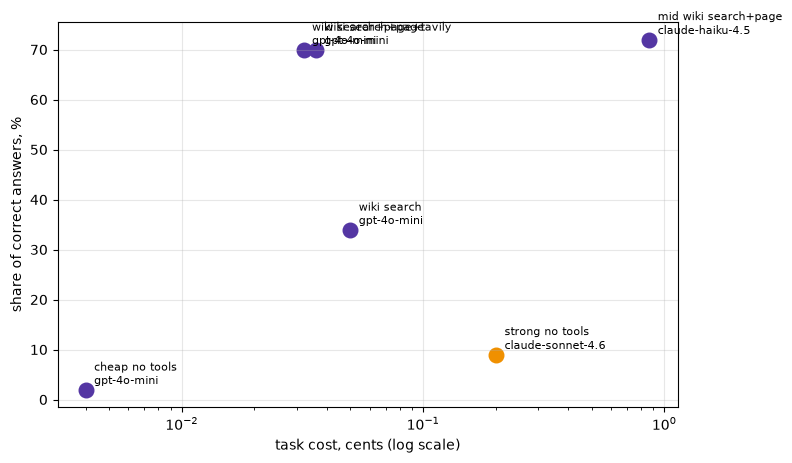

In [29]:
homework = pd.concat([base_results, mid_results], ignore_index=True)
suffix = f"sample_{len(tasks)}" if TASK_LIMIT else "full"
homework.to_csv(f"results_raw_{suffix}.csv", index=False)
homework_table = report(homework)
Path(f"results_{suffix}.md").write_text(homework_table.to_string(index=False), encoding="utf-8")
money_chart(homework_table, f"img/homework_{suffix}.png")
homework_table

## Cascade run

The seminar cascade: the cheap agent answers with a stated confidence, tasks below the threshold go to the mid agent, answers are memoized per task so each model answers a task at most once. The mid run from the main table is already paid for, so `seed_memo` puts `mid_results` into `MEMO` and the mid agent is not called again. The cheap agent answers every task live.

In [30]:
seed_memo(mid_results, MODELS["mid"])
cascade_df = cascade_sweep(tasks, [0.0, 0.7, 0.85, 0.95])
cascade_df

,threshold,accuracy,cost_per_task,avg_steps,avg_seconds,escalated,cost_per_correct
0,0.00,0.70199,0.00044,3.76159,8.04200,0.00000,0.00063
1,0.70,0.72848,0.00181,4.31126,10.91418,0.07947,0.00248
2,0.85,0.74834,0.00280,4.73510,13.20690,0.15232,0.00374
3,0.95,0.76821,0.00417,5.41722,16.83273,0.33775,0.00543


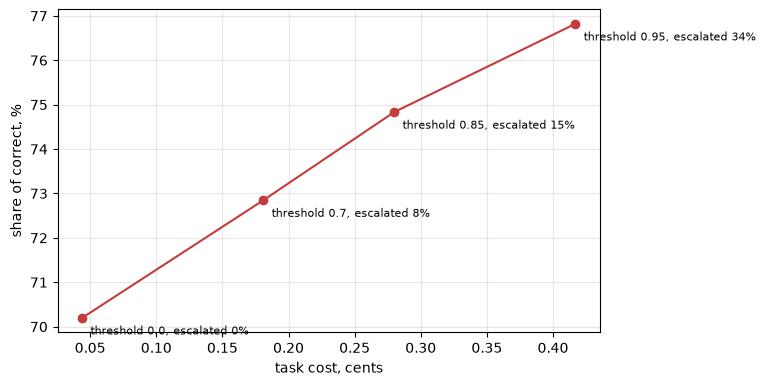

In [31]:
cascade_chart(cascade_df);

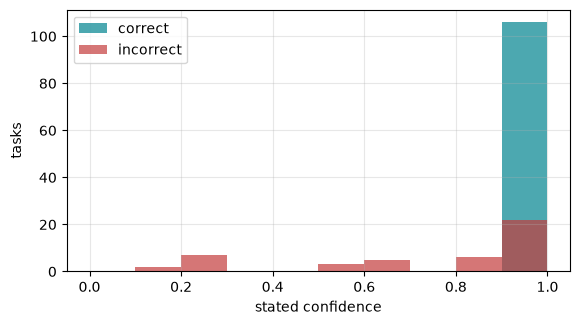

In [32]:
confidence_chart(tasks, MODELS["cheap"]);

,config,model,n,accuracy,cost_per_task,cost_per_correct,avg_steps,avg_seconds
0,cheap no tools,gpt-4o-mini,151,0.02000,0.00004,0.00205,1.00000,1.70000
1,wiki search+page+tavily,gpt-4o-mini,151,0.70000,0.00032,0.00045,2.89000,6.40000
2,wiki search+page,gpt-4o-mini,151,0.70000,0.00036,0.00052,3.42000,6.50000
3,wiki search,gpt-4o-mini,151,0.34000,0.00050,0.00149,4.43000,9.70000
4,strong no tools,claude-sonnet-4.6,151,0.09000,0.00201,0.02170,1.00000,5.60000
5,mid wiki search+page,claude-haiku-4.5,151,0.72000,0.00867,0.01201,4.08000,24.40000
6,"cascade wiki search+page, threshold 0.0",mini + haiku,151,0.70199,0.00044,0.00063,3.76159,8.04200
7,"cascade wiki search+page, threshold 0.7",mini + haiku,151,0.72848,0.00181,0.00248,4.31126,10.91418
8,"cascade wiki search+page, threshold 0.85",mini + haiku,151,0.74834,0.00280,0.00374,4.73510,13.20690
9,"cascade wiki search+page, threshold 0.95",mini + haiku,151,0.76821,0.00417,0.00543,5.41722,16.83273


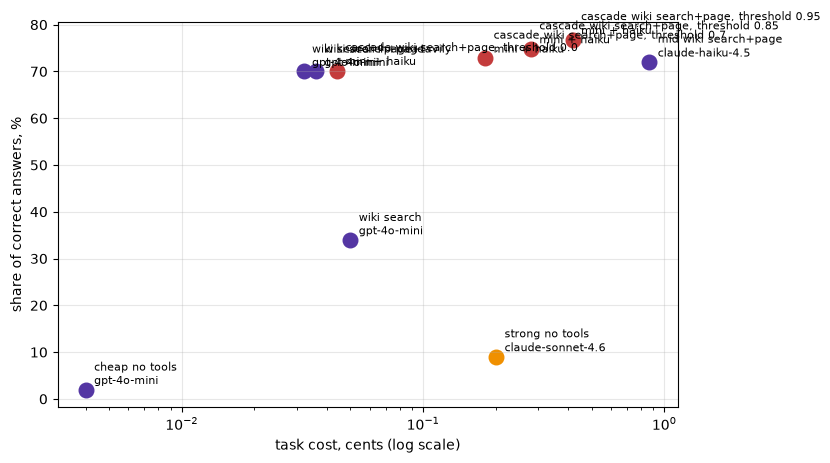

In [33]:
extra = pd.DataFrame([{"config": f"cascade {best_config}, threshold {r.threshold}", "model": "mini + haiku", "n": len(tasks),
                       "accuracy": r.accuracy, "cost_per_task": r.cost_per_task, "cost_per_correct": r.cost_per_correct,
                       "avg_steps": r.avg_steps, "avg_seconds": r.avg_seconds} for r in cascade_df.itertuples()])
final_table = pd.concat([homework_table, extra], ignore_index=True)
Path(f"results_with_cascade_{suffix}.md").write_text(final_table.to_string(index=False), encoding="utf-8")
money_chart(final_table, f"img/homework_with_cascade_{suffix}.png")
final_table